In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!pip install ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 73.3 MB/s eta 0:00:00


In [ ]:
import os
path = '/content/drive/MyDrive/southacid/'
if os.path.exists(path):
    print("폴더 내 파일 목록:", os.listdir(path))
else:
    print("해당 폴더 경로가 존재하지 않습니다. 마운트 상태를 확인하세요.")

폴더 내 파일 목록: ['README.dataset.txt', 'README.roboflow.txt', 'valid', 'train', 'test', 'data.yaml']


In [ ]:
import torch
import os
import xml.etree.ElementTree as ET
from PIL import Image
from torch.utils.data import Dataset

class NamsanDataset(Dataset):
    def __init__(self, root_dir, S=7, B=2, C=1, transform=None):
        """
        root_dir: 'train' 폴더의 경로
        """
        self.root_dir = root_dir
        self.transform = transform
        self.S = S
        self.B = B
        self.C = C

        # 필터링 로직: .jpg 확장자이면서 'n_tower'가 포함된 파일명 리스트 생성
        self.filenames = []
        all_files = os.listdir(root_dir)

        for f in all_files:
            if f.endswith('.jpg') and 'n_tower' in f:
                base_name = os.path.splitext(f)[0]
                # 대응하는 xml 파일이 존재하는지도 체크 (안전장치)
                if f"{base_name}.xml" in all_files:
                    self.filenames.append(base_name)

        print(f"총 {len(self.filenames)}개의 남산 타워 데이터를 찾았습니다.")

    def __len__(self):
        return len(self.filenames)

    def __getitem__(self, index):
        fname = self.filenames[index]
        # 같은 폴더(root_dir) 내에서 jpg와 xml을 모두 찾음
        img_path = os.path.join(self.root_dir, fname + '.jpg')
        xml_path = os.path.join(self.root_dir, fname + '.xml')

        image = Image.open(img_path).convert("RGB")
        boxes = self._parse_xml(xml_path)

        if self.transform:
            image = self.transform(image)

        target = torch.zeros((self.S, self.S, self.C + self.B * 5))

        for box in boxes:
            class_label, x, y, w, h = box
            i, j = int(self.S * y), int(self.S * x)
            x_cell, y_cell = self.S * x - j, self.S * y - i

            if target[i, j, 0] == 0:
                target[i, j, 0] = 1
                # 박스 좌표 및 신뢰도(1.0) 입력
                target[i, j, 1:6] = torch.tensor([x_cell, y_cell, w, h, 1.0])

        return image, target

    def _parse_xml(self, xml_path):
        tree = ET.parse(xml_path)
        root = tree.getroot()
        size = root.find("size")
        width = int(size.find("width").text)
        height = int(size.find("height").text)

        boxes = []
        for obj in root.findall("object"):
            # ✨ 객체 이름 확인 추가
            obj_name = obj.find("name").text
            if obj_name != "n_tower":  # 또는 "namsan_tower" 등 실제 라벨명 확인 필요
                continue  # 남산 타워가 아니면 건너뛰기

            xmlbox = obj.find("bndbox")
            xmin = float(xmlbox.find("xmin").text)
            ymin = float(xmlbox.find("ymin").text)
            xmax = float(xmlbox.find("xmax").text)
            ymax = float(xmlbox.find("ymax").text)

            x = (xmin + xmax) / (2.0 * width)
            y = (ymin + ymax) / (2.0 * height)
            w = (xmax - xmin) / width
            h = (ymax - ymin) / height

            boxes.append([0, x, y, w, h])
        return boxes

In [ ]:
import xml.etree.ElementTree as ET

# 샘플 XML 파일 하나 열어보기
sample_xml = "/content/drive/MyDrive/southacid/test/n_tower_348_jpg.rf.841978cb82828d3fc2188dc03db2f0e0.xml"
tree = ET.parse(sample_xml)
for obj in tree.getroot().findall("object"):
    print(f"객체 이름: {obj.find('name').text}")

객체 이름: n_tower


In [ ]:
from torchvision import transforms
from torch.utils.data import DataLoader

# 이미지 전처리 (ImageNet 사전학습 가중치를 쓸 계획이라면 Normalize 추가 권장)
transform = transforms.Compose([
    transforms.Resize((448, 448)),
    transforms.ToTensor(),
    # transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]) # 사전학습 모델용
])

# 경로를 실제 train 폴더로 지정하세요
dataset_path = "/content/drive/MyDrive/southacid/train"

train_dataset = NamsanDataset(
    root_dir=dataset_path,
    transform=transform
)

train_loader = DataLoader(dataset=train_dataset, batch_size=16, shuffle=True)

# 제대로 불러와지는지 확인
img, tar = next(iter(train_loader))
print(f"배치 이미지 형상: {img.shape}") # [16, 3, 448, 448]
print(f"배치 타겟 형상: {tar.shape}")   # [16, 7, 7, 11]

총 351개의 남산 타워 데이터를 찾았습니다.
배치 이미지 형상: torch.Size([16, 3, 448, 448])
배치 타겟 형상: torch.Size([16, 7, 7, 11])


In [ ]:
import torch

def intersection_over_union(boxes_preds, boxes_labels):
    """
    boxes_preds shape: (batch_size, 4) -> [x, y, w, h]
    boxes_labels shape: (batch_size, 4) -> [x, y, w, h]
    """
    # 중심 좌표(x, y, w, h)를 (x1, y1, x2, y2) 코너 좌표로 변환
    box1_x1 = boxes_preds[..., 0:1] - boxes_preds[..., 2:3] / 2
    box1_y1 = boxes_preds[..., 1:2] - boxes_preds[..., 3:4] / 2
    box1_x2 = boxes_preds[..., 0:1] + boxes_preds[..., 2:3] / 2
    box1_y2 = boxes_preds[..., 1:2] + boxes_preds[..., 3:4] / 2

    box2_x1 = boxes_labels[..., 0:1] - boxes_labels[..., 2:3] / 2
    box2_y1 = boxes_labels[..., 1:2] - boxes_labels[..., 3:4] / 2
    box2_x2 = boxes_labels[..., 0:1] + boxes_labels[..., 2:3] / 2
    box2_y2 = boxes_labels[..., 1:2] + boxes_labels[..., 3:4] / 2

    # 교집합(Intersection) 영역의 좌표 계산
    x1 = torch.max(box1_x1, box2_x1)
    y1 = torch.max(box1_y1, box2_y1)
    x2 = torch.min(box1_x2, box2_x2)
    y2 = torch.min(box1_y2, box2_y2)

    # .clamp(0)는 겹치지 않는 경우(음수)를 0으로 만듦
    intersection = (x2 - x1).clamp(0) * (y2 - y1).clamp(0)

    # 합집합(Union) 영역 계산
    box1_area = abs((box1_x2 - box1_x1) * (box1_y2 - box1_y1))
    box2_area = abs((box2_x2 - box2_x1) * (box2_y2 - box2_y1))

    return intersection / (box1_area + box2_area - intersection + 1e-6)

In [ ]:
import torch.nn as nn

class YoloLoss(nn.Module):
    def __init__(self, S=7, B=2, C=1):
        super(YoloLoss, self).__init__()
        self.mse = nn.MSELoss(reduction="sum")
        self.S = S
        self.B = B
        self.C = C
        self.lambda_noobj = 0.5
        self.lambda_coord = 5

    def forward(self, predictions, target):
        predictions = predictions.reshape(-1, self.S, self.S, self.C + self.B * 5)

        # IoU 계산 (박스 1, 박스 2 각각)
        iou_b1 = intersection_over_union(predictions[..., 1:5], target[..., 1:5])
        iou_b2 = intersection_over_union(predictions[..., 6:10], target[..., 1:5])
        ious = torch.cat([iou_b1.unsqueeze(0), iou_b2.unsqueeze(0)], dim=0)

        _, best_box = torch.max(ious, dim=0)
        exists_box = target[..., 0].unsqueeze(3)

        # 1. Coordinate Loss
        box_predictions = exists_box * (
            best_box * predictions[..., 6:10] + (1 - best_box) * predictions[..., 1:5]
        )
        box_targets = exists_box * target[..., 1:5]

        # w, h에 루트 적용 (작은 박스의 오차에 더 민감하게 반응하도록)
        box_predictions[..., 2:4] = torch.sign(box_predictions[..., 2:4]) * torch.sqrt(torch.abs(box_predictions[..., 2:4] + 1e-6))
        box_targets[..., 2:4] = torch.sqrt(box_targets[..., 2:4])

        coord_loss = self.mse(torch.flatten(box_predictions, end_dim=-2),
                              torch.flatten(box_targets, end_dim=-2))

        # 2. Object Loss
        pred_conf = exists_box * (
            best_box * predictions[..., 10:11] + (1 - best_box) * predictions[..., 5:6]
        )
        object_loss = self.mse(torch.flatten(exists_box * pred_conf),
                               torch.flatten(exists_box * target[..., 0:1]))

        # 3. No Object Loss
        no_object_loss = self.mse(torch.flatten((1 - exists_box) * predictions[..., 5:6], start_dim=1),
                                  torch.flatten((1 - exists_box) * target[..., 0:1], start_dim=1))
        no_object_loss += self.mse(torch.flatten((1 - exists_box) * predictions[..., 10:11], start_dim=1),
                                   torch.flatten((1 - exists_box) * target[..., 0:1], start_dim=1))

        # 4. Class Loss
        class_loss = self.mse(torch.flatten(exists_box * predictions[..., :self.C], end_dim=-2),
                              torch.flatten(exists_box * target[..., :self.C], end_dim=-2))

        total_loss = (self.lambda_coord * coord_loss + object_loss +
                      self.lambda_noobj * no_object_loss + class_loss)

        return total_loss

In [ ]:
import torch
import torch.nn as nn

# 1. 아키텍처 설정 (마지막에 "M" 추가됨)
architecture_config = [
    (7, 64, 2, 3),   # 448 -> 224
    "M",             # 224 -> 112
    (3, 192, 1, 1),  # 112 -> 112
    "M",             # 112 -> 56
    (1, 128, 1, 0),
    (3, 256, 1, 1),
    (1, 256, 1, 0),
    (3, 512, 1, 1),
    "M",             # 56 -> 28
    (3, 1024, 1, 1),
    (3, 1024, 2, 1), # 28 -> 14 (Stride 2 사용됨)
    (3, 1024, 1, 1),
    (3, 1024, 1, 1),
    "M",             # 14 -> 7 (이 부분이 추가되어야 S=7과 일치함)
]

# CNNBlock과 Yolov1 클래스는 이전과 동일하되, 위 config를 참조하도록 다시 선언
class CNNBlock(nn.Module):
    def __init__(self, in_channels, out_channels, **kwargs):
        super(CNNBlock, self).__init__()
        self.conv = nn.Conv2d(in_channels, out_channels, bias=False, **kwargs)
        self.batchnorm = nn.BatchNorm2d(out_channels)
        self.leakyrelu = nn.LeakyReLU(0.1)

    def forward(self, x):
        return self.leakyrelu(self.batchnorm(self.conv(x)))

class Yolov1(nn.Module):
    def __init__(self, in_channels=3, **kwargs):
        super(Yolov1, self).__init__()
        self.architecture = architecture_config
        self.in_channels = in_channels
        self.darknet = self._create_conv_layers(self.architecture)
        self.fcs = self._create_fcs(**kwargs)

    def forward(self, x):
        x = self.darknet(x)
        return self.fcs(torch.flatten(x, start_dim=1))

    def _create_conv_layers(self, architecture):
        layers = []
        in_channels = self.in_channels
        for x in architecture:
            if type(x) == tuple:
                layers += [CNNBlock(in_channels, x[1], kernel_size=x[0], stride=x[2], padding=x[3])]
                in_channels = x[1]
            elif type(x) == str:
                layers += [nn.MaxPool2d(kernel_size=2, stride=2)]
        return nn.Sequential(*layers)

    def _create_fcs(self, split_size=7, num_boxes=2, num_classes=1):
        S, B, C = split_size, num_boxes, num_classes
        return nn.Sequential(
            nn.Flatten(),
            nn.Linear(1024 * S * S, 496),
            nn.Dropout(0.0),
            nn.LeakyReLU(0.1),
            nn.Linear(496, S * S * (C + B * 5)),
        )

학습 시작 장치: cuda
Epoch [1/50] - Loss: 120.2070
Epoch [10/50] - Loss: 12.6381
Epoch [20/50] - Loss: 7.8478
Epoch [30/50] - Loss: 10.3439
Epoch [40/50] - Loss: 11.4572
Epoch [50/50] - Loss: 9.4458


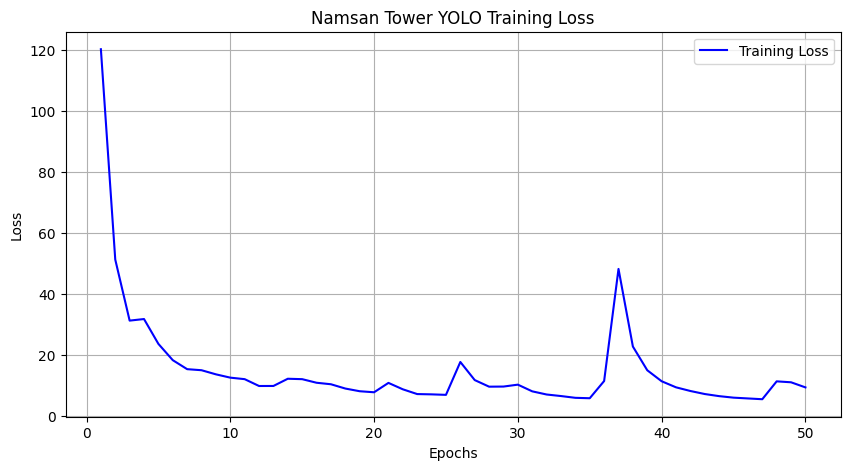

In [ ]:
import matplotlib.pyplot as plt
import torch.optim as optim

# 하이퍼파라미터 설정
LEARNING_RATE = 2e-5
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
EPOCHS = 50

# 1. 모델 초기화 (이제 Yolov1을 인식합니다)
model = Yolov1(split_size=7, num_boxes=2, num_classes=1).to(DEVICE)
optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE, weight_decay=0.0005)
loss_fn = YoloLoss() # 이전에 정의한 YoloLoss 클래스 사용

loss_history = []

print(f"학습 시작 장치: {DEVICE}")

# 2. 학습 루프
for epoch in range(EPOCHS):
    model.train()
    total_epoch_loss = 0

    for batch_idx, (images, targets) in enumerate(train_loader):
        images, targets = images.to(DEVICE), targets.to(DEVICE)

        outputs = model(images)
        loss = loss_fn(outputs, targets)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_epoch_loss += loss.item()

    avg_loss = total_epoch_loss / len(train_loader)
    loss_history.append(avg_loss)

    if (epoch + 1) % 10 == 0 or epoch == 0:
        print(f"Epoch [{epoch+1}/{EPOCHS}] - Loss: {avg_loss:.4f}")

# 3. 시각화
plt.figure(figsize=(10, 5))
plt.plot(range(1, EPOCHS + 1), loss_history, label='Training Loss', color='blue')
plt.title('Namsan Tower YOLO Training Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
import cv2
import xml.etree.ElementTree as ET

def get_ground_truth_from_xml(xml_path, width=448, height=448):
    """XML 파일에서 정답 박스 정보를 [x, y, w, h] 리스트로 가져옴"""
    tree = ET.parse(xml_path)
    root = tree.getroot()
    size = root.find("size")
    orig_w = int(size.find("width").text)
    orig_h = int(size.find("height").text)

    gt_boxes = []
    for obj in root.findall("object"):
        xmlbox = obj.find("bndbox")
        xmin = float(xmlbox.find("xmin").text) / orig_w
        ymin = float(xmlbox.find("ymin").text) / orig_h
        xmax = float(xmlbox.find("xmax").text) / orig_w
        ymax = float(xmlbox.find("ymax").text) / orig_h

        # YOLO 형식 [center_x, center_y, width, height]
        cx, cy = (xmin + xmax) / 2, (ymin + ymax) / 2
        bw, bh = xmax - xmin, ymax - ymin
        gt_boxes.append([cx, cy, bw, bh])
    return gt_boxes

def plot_comparison(image, pred_boxes, gt_boxes):
    """예측(Red)과 정답(Green)을 함께 시각화"""
    if isinstance(image, torch.Tensor):
        image = image.permute(1, 2, 0).cpu().numpy()

    plt.figure(figsize=(8, 8))
    plt.imshow(image)
    ax = plt.gca()
    h, w, _ = image.shape

    # 1. 정답 박스 그리기 (Green)
    for box in gt_boxes:
        # [cx, cy, bw, bh] -> [x1, y1, w, h]
        rect = patches.Rectangle(
            ((box[0] - box[2]/2) * w, (box[1] - box[3]/2) * h),
            box[2] * w, box[3] * h,
            linewidth=3, edgecolor="lime", facecolor="none", label='Ground Truth'
        )
        ax.add_patch(rect)
        plt.text((box[0] - box[2]/2) * w, (box[1] - box[3]/2) * h, "Truth", color="lime", weight="bold")

    # 2. 예측 박스 그리기 (Red)
    for box in pred_boxes:
        conf = box[1]
        b = box[2:] # [cx, cy, bw, bh]
        rect = patches.Rectangle(
            ((b[0] - b[2]/2) * w, (b[1] - b[3]/2) * h),
            b[2] * w, b[3] * h,
            linewidth=2, edgecolor="red", facecolor="none", linestyle="--", label='Prediction'
        )
        ax.add_patch(rect)
        plt.text((b[0] - b[2]/2) * w, (b[1] - b[3]/2) * h + 20, f"Pred:{conf:.2f}", color="red", weight="bold")

    plt.title("Comparison: Green(Truth) vs Red(Prediction)")
    plt.axis("off")
    plt.show()

In [ ]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import xml.etree.ElementTree as ET
from PIL import Image

# 1. NMS를 위한 IoU 계산
def iou_corners(box1, box2):
    x1 = torch.max(box1[0], box2[0])
    y1 = torch.max(box1[1], box2[1])
    x2 = torch.min(box1[2], box2[2])
    y2 = torch.min(box1[3], box2[3])
    intersection = (x2 - x1).clamp(0) * (y2 - y1).clamp(0)
    box1_area = abs((box1[2] - box1[0]) * (box1[3] - box1[1]))
    box2_area = abs((box2[2] - box2[0]) * (box2[3] - box2[1]))
    return intersection / (box1_area + box2_area - intersection + 1e-6)

# 2. Non-Maximum Suppression (중복 박스 제거)
def non_max_suppression(bboxes, iou_threshold, threshold):
    bboxes = [box for box in bboxes if box[1] > threshold]
    bboxes = sorted(bboxes, key=lambda x: x[1], reverse=True)
    bboxes_after_nms = []
    while bboxes:
        chosen_box = bboxes.pop(0)
        bboxes_after_nms.append(chosen_box)
        bboxes = [
            box for box in bboxes
            if iou_corners(torch.tensor(chosen_box[2:]), torch.tensor(box[2:])) < iou_threshold
        ]
    return bboxes_after_nms

# 3. 모델 출력 텐서를 바운딩 박스로 변환
def convert_cellboxes(predictions, S=7, C=1):
    batch_size = predictions.shape[0]
    predictions = predictions.reshape(-1, S, S, C + 10) # 11차원 가정
    predictions = predictions.to("cpu")

    bboxes1 = predictions[..., 1:5]
    bboxes2 = predictions[..., 6:10]
    scores = torch.cat((predictions[..., 0].unsqueeze(0), predictions[..., 5].unsqueeze(0)), dim=0)
    best_box = scores.argmax(0).unsqueeze(-1)

    best_boxes = bboxes1 * (1 - best_box) + best_box * bboxes2
    cell_indices = torch.arange(S).repeat(batch_size, S, 1).unsqueeze(-1)

    x = 1 / S * (best_boxes[..., :1] + cell_indices)
    y = 1 / S * (best_boxes[..., 1:2] + cell_indices.permute(0, 2, 1, 3))
    w_h = best_boxes[..., 2:4]

    converted_bboxes = torch.cat((predictions[..., :C].argmax(-1).unsqueeze(-1),
                                  scores.max(0)[0].unsqueeze(-1),
                                  x, y, w_h), dim=-1)
    return converted_bboxes.reshape(batch_size, S*S, -1)

# 4. 정답 vs 예측 시각화
def plot_comparison(image, pred_boxes, gt_boxes):
    if isinstance(image, torch.Tensor):
        image = image.permute(1, 2, 0).cpu().numpy()

    fig, ax = plt.subplots(figsize=(8, 8))
    ax.imshow(image)
    h, w, _ = image.shape

    # 정답: 녹색 실선
    for box in gt_boxes:
        rect = patches.Rectangle(
            ((box[0] - box[2]/2) * w, (box[1] - box[3]/2) * h),
            box[2] * w, box[3] * h,
            linewidth=3, edgecolor="lime", facecolor="none"
        )
        ax.add_patch(rect)
        ax.text((box[0] - box[2]/2) * w, (box[1] - box[3]/2) * h - 5, "Truth", color="lime", weight="bold")

    # 예측: 빨간 점선
    for box in pred_boxes:
        conf = box[1]
        b = box[2:]
        rect = patches.Rectangle(
            ((b[0] - b[2]/2) * w, (b[1] - b[3]/2) * h),
            b[2] * w, b[3] * h,
            linewidth=2, edgecolor="red", facecolor="none", linestyle="--"
        )
        ax.add_patch(rect)
        ax.text((b[0] - b[2]/2) * w, (b[1] - b[3]/2) * h + 20, f"Pred:{conf:.2f}", color="red", weight="bold")

    plt.title("Green: Truth | Red: Prediction")
    plt.axis("off")
    plt.show()

In [ ]:
def get_ground_truth_from_xml(xml_path):
    tree = ET.parse(xml_path)
    root = tree.getroot()
    size = root.find("size")
    width = int(size.find("width").text)
    height = int(size.find("height").text)

    gt_boxes = []
    for obj in root.findall("object"):
        xmlbox = obj.find("bndbox")
        xmin, ymin = float(xmlbox.find("xmin").text), float(xmlbox.find("ymin").text)
        xmax, ymax = float(xmlbox.find("xmax").text), float(xmlbox.find("ymax").text)

        cx, cy = (xmin + xmax) / (2.0 * width), (ymin + ymax) / (2.0 * height)
        bw, bh = (xmax - xmin) / width, (ymax - ymin) / height
        gt_boxes.append([cx, cy, bw, bh])
    return gt_boxes

In [ ]:
def calculate_metrics(model, loader, iou_threshold=0.5, conf_threshold=0.4):
    all_pred_boxes = []
    all_true_boxes = []

    model.eval()
    train_idx = 0

    for x, y in loader:
        x = x.to(DEVICE)
        with torch.no_grad():
            predictions = model(x)

        batch_size = x.shape[0]
        bboxes = convert_cellboxes(predictions) # [batch, S*S, 6]

        for idx in range(batch_size):
            # 1. 예측값 필터링 및 NMS 적용
            current_preds = bboxes[idx].tolist()
            # Corner 변환 로직 (이전 코드 활용)
            corners = [[p[0], p[1], p[2]-p[4]/2, p[3]-p[5]/2, p[2]+p[4]/2, p[3]+p[5]/2] for p in current_preds]
            nms_preds = non_max_suppression(corners, iou_threshold=0.45, threshold=conf_threshold)

            for pred in nms_preds:
                all_pred_boxes.append([train_idx] + pred)

            # 2. 정답값 저장
            ground_truth = y[idx] # [7, 7, 11]
            for i in range(7):
                for j in range(7):
                    if ground_truth[i, j, 0] == 1: # 객체 존재
                        # 정답은 [train_idx, class, conf, x1, y1, x2, y2] 형태로 저장
                        # 정답 x,y,w,h를 corner로 변환 필요
                        cx, cy, w, h = ground_truth[i, j, 1:5].tolist()
                        # 주의: Dataset의 정답 생성 방식에 따라 좌표 복원 필요
                        all_true_boxes.append([train_idx, 0, 1.0, cx-w/2, cy-h/2, cx+w/2, cy+h/2])
            train_idx += 1

    # TP, FP 계산 (IoU 기준)
    tp = 0
    fp = 0
    total_true_boxes = len(all_true_boxes)

    # 이미지별로 정답 박스 사용 여부 체크
    used_true_boxes = [False] * total_true_boxes

    # 신뢰도 순 정렬
    all_pred_boxes.sort(key=lambda x: x[2], reverse=True)

    for pred in all_pred_boxes:
        img_idx = pred[0]
        best_iou = 0
        best_gt_idx = -1

        for i, gt in enumerate(all_true_boxes):
            if gt[0] == img_idx and not used_true_boxes[i]:
                iou = iou_corners(torch.tensor(pred[3:]), torch.tensor(gt[3:]))
                if iou > best_iou:
                    best_iou = iou
                    best_gt_idx = i

        if best_iou >= iou_threshold:
            tp += 1
            used_true_boxes[best_gt_idx] = True
        else:
            fp += 1

    fn = total_true_boxes - tp

    precision = tp / (tp + fp + 1e-6)
    recall = tp / (total_true_boxes + 1e-6)
    f1 = 2 * (precision * recall) / (precision + recall + 1e-6)

    return precision, recall, f1

# 실행 예시
p, r, f1 = calculate_metrics(model, train_loader, conf_threshold=0.5)
print(f"Precision: {p:.4f}, Recall: {r:.4f}, F1-score: {f1:.4f}")

Precision: 0.0084, Recall: 0.1493, F1-score: 0.0159


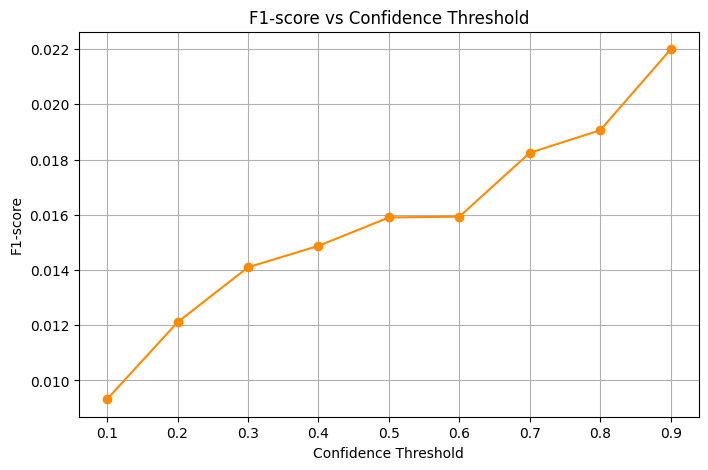

In [ ]:
conf_levels = np.linspace(0.1, 0.9, 9)
f1_scores = []

for c in conf_levels:
    _, _, f1 = calculate_metrics(model, train_loader, conf_threshold=c)
    f1_scores.append(f1)

plt.figure(figsize=(8, 5))
plt.plot(conf_levels, f1_scores, marker='o', linestyle='-', color='darkorange')
plt.title('F1-score vs Confidence Threshold')
plt.xlabel('Confidence Threshold')
plt.ylabel('F1-score')
plt.grid(True)
plt.show()

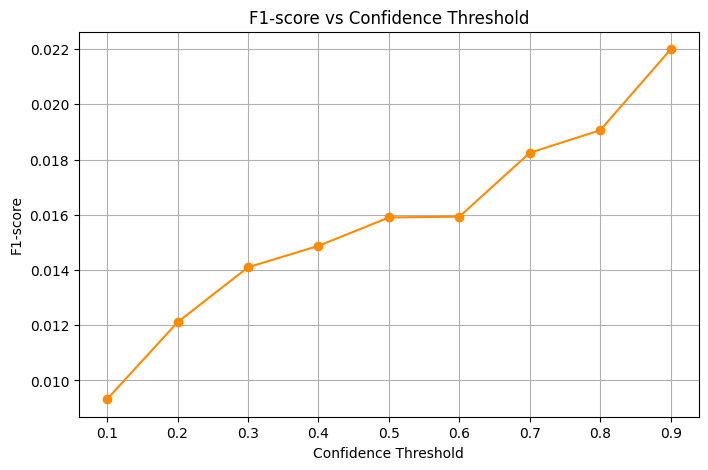

In [ ]:
conf_levels = np.linspace(0.1, 0.9, 9)
f1_scores = []

for c in conf_levels:
    _, _, f1 = calculate_metrics(model, train_loader, conf_threshold=c)
    f1_scores.append(f1)

plt.figure(figsize=(8, 5))
plt.plot(conf_levels, f1_scores, marker='o', linestyle='-', color='darkorange')
plt.title('F1-score vs Confidence Threshold')
plt.xlabel('Confidence Threshold')
plt.ylabel('F1-score')
plt.grid(True)
plt.show()

--- Result for: n_tower_516_jpg.rf.e46665907f3705bf365e4d801f171a7f.jpg ---


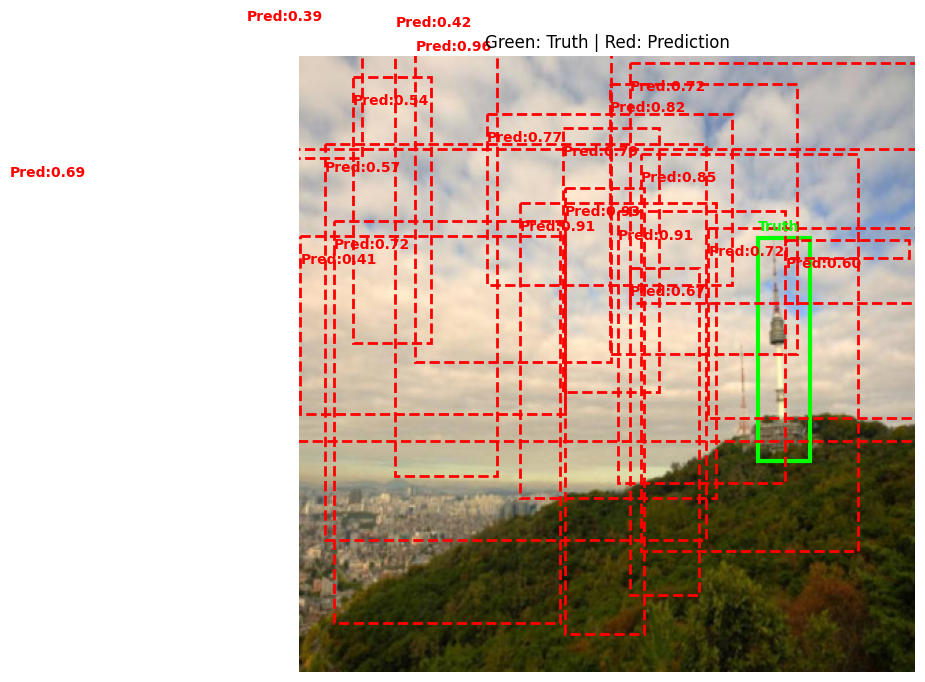

--- Result for: n_tower_179_jpg.rf.1b669bdb18394a49aef3622f28e9b23e.jpg ---


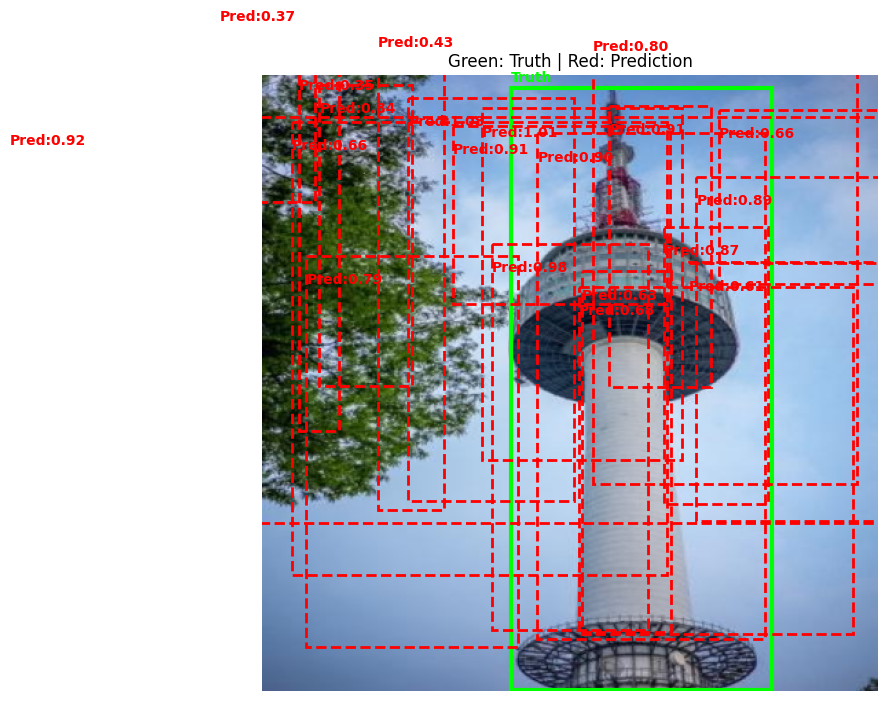

--- Result for: n_tower_336_jpg.rf.6c301cf9590c9a485d236b5814022a3c.jpg ---


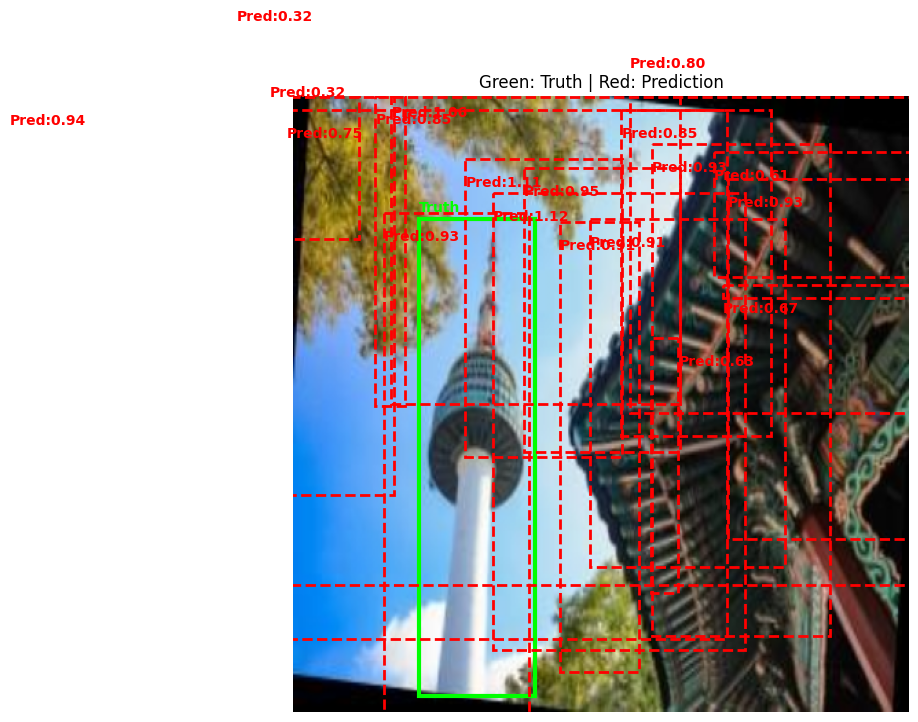

In [ ]:
import os

test_dir = "/content/drive/MyDrive/southacid/test"
model.eval()

# 테스트 폴더에서 n_tower .jpg 파일들 리스트업
test_images = [f for f in os.listdir(test_dir) if f.endswith('.jpg') and 'n_tower' in f]

# 상위 3개만 테스트해보기 (개수는 [:3]을 수정해서 조절하세요)
for img_name in test_images:
    base_name = os.path.splitext(img_name)[0]
    img_path = os.path.join(test_dir, img_name)
    xml_path = os.path.join(test_dir, base_name + ".xml")

    if not os.path.exists(xml_path):
        continue

    # 1. 이미지 로드 및 전처리
    raw_image = Image.open(img_path).convert("RGB")
    transformed_image = transform(raw_image).unsqueeze(0).to(DEVICE)

    with torch.no_grad():
        # 2. 모델 예측
        predictions = model(transformed_image)

        # 3. 박스 변환 및 NMS 적용
        bboxes = convert_cellboxes(predictions, S=7, C=1)
        bboxes = bboxes[0].tolist()

        # Corner 변환 for NMS
        bboxes_corners = []
        for box in bboxes:
            xc, yc, bw, bh = box[2:]
            bboxes_corners.append([box[0], box[1], xc - bw/2, yc - bh/2, xc + bw/2, yc + bh/2])

        # NMS 필터링 (임계값 조절 가능)
        nms_boxes_corners = non_max_suppression(bboxes_corners, iou_threshold=0.45, threshold=0.3)

        # 시각화용 cx, cy, w, h로 재변환
        final_preds = []
        for box in nms_boxes_corners:
            x1, y1, x2, y2 = box[2:]
            final_preds.append([box[0], box[1], (x1+x2)/2, (y1+y2)/2, x2-x1, y2-y1])

    # 4. XML에서 정답 가져오기
    ground_truth = get_ground_truth_from_xml(xml_path)

    # 5. 시각화 호출
    print(f"--- Result for: {img_name} ---")
    plot_comparison(transformed_image[0], final_preds, ground_truth)

In [ ]:
path = 'content/example'

총 9개의 PNG 파일을 처리합니다.
--- [Inference Result]: image (1).png ---


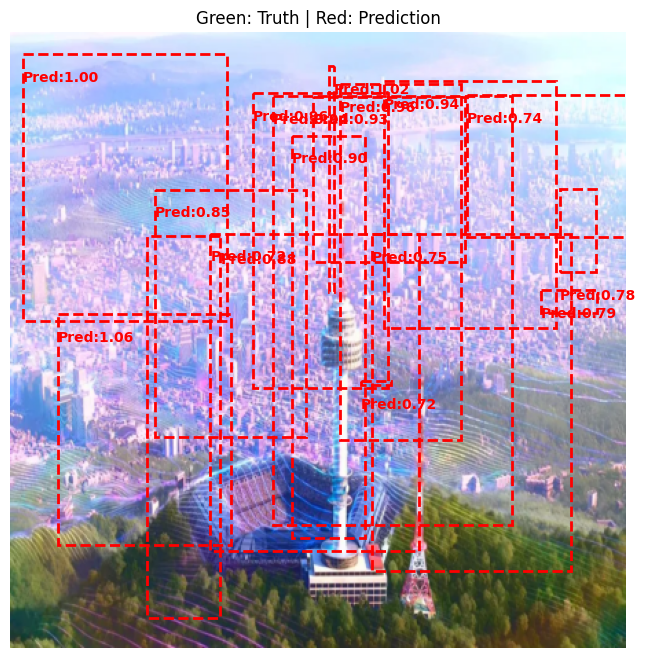

--- [Inference Result]: image (10).png ---


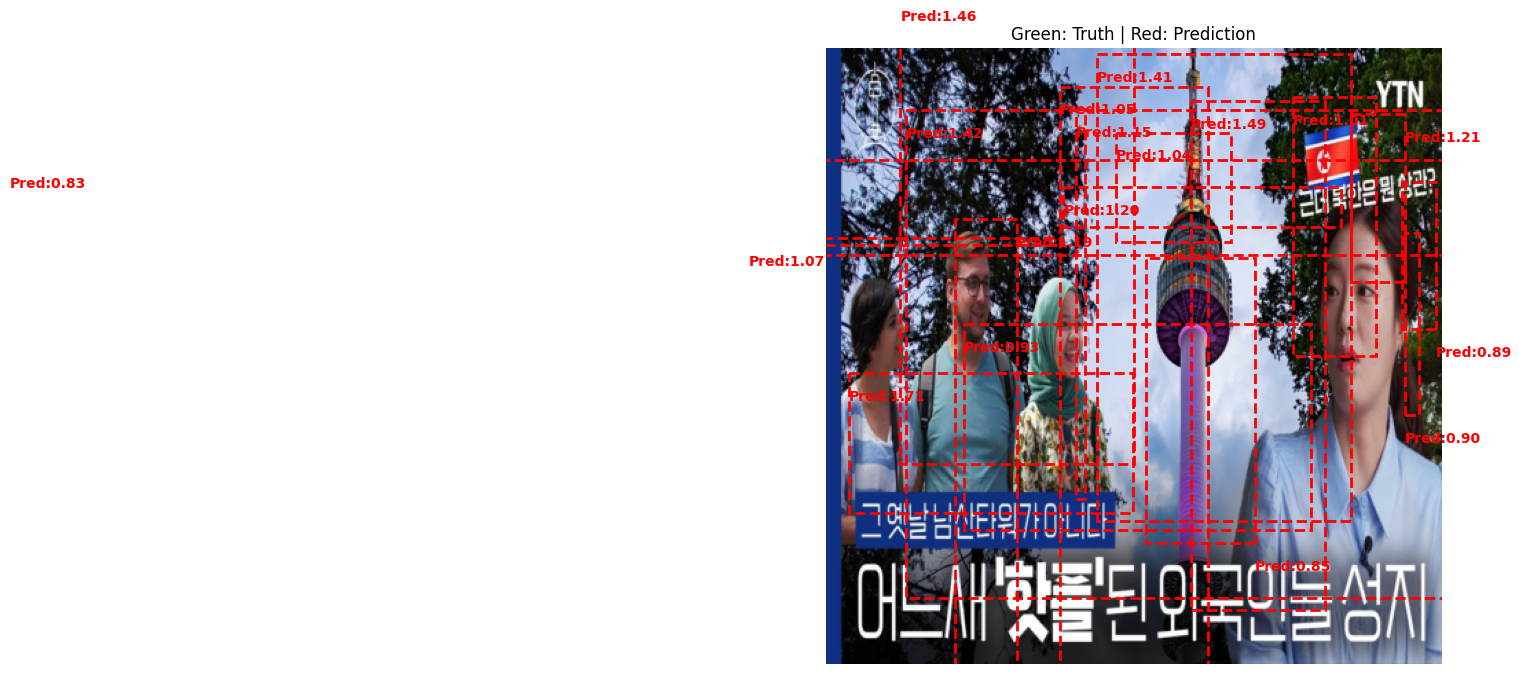

--- [Inference Result]: image.png ---


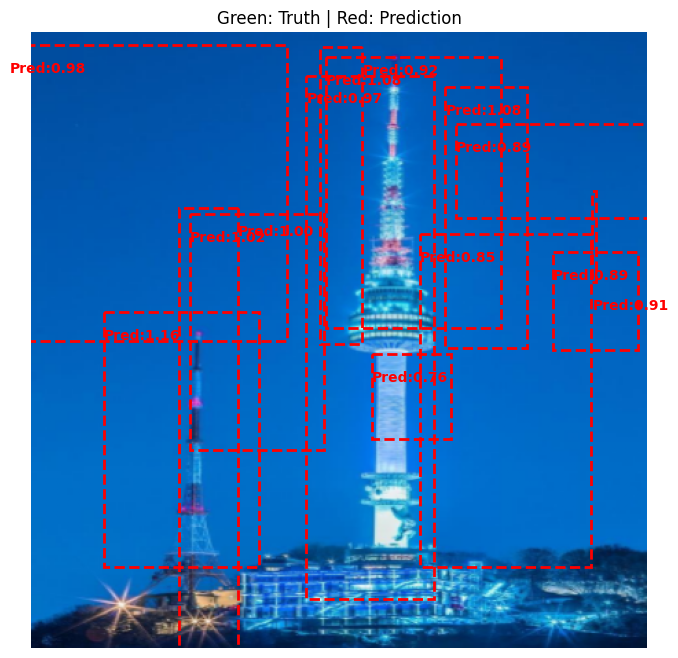

--- [Inference Result]: image (4).png ---


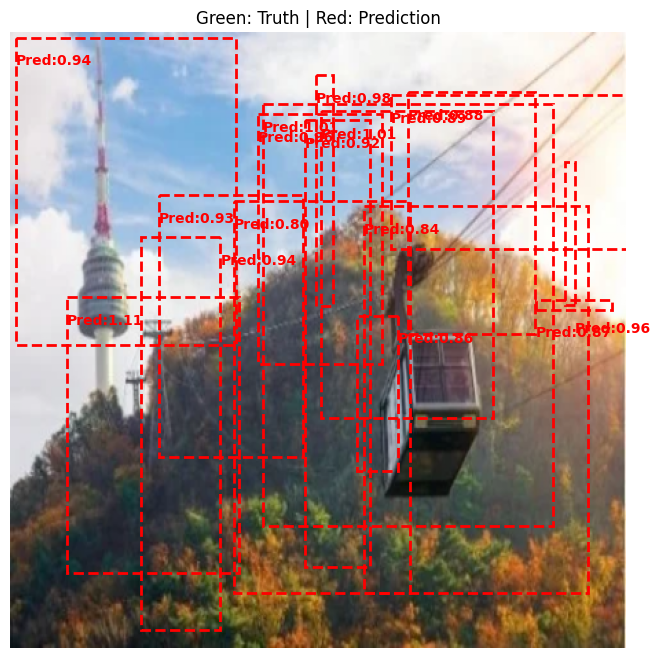

--- [Inference Result]: image (2).png ---


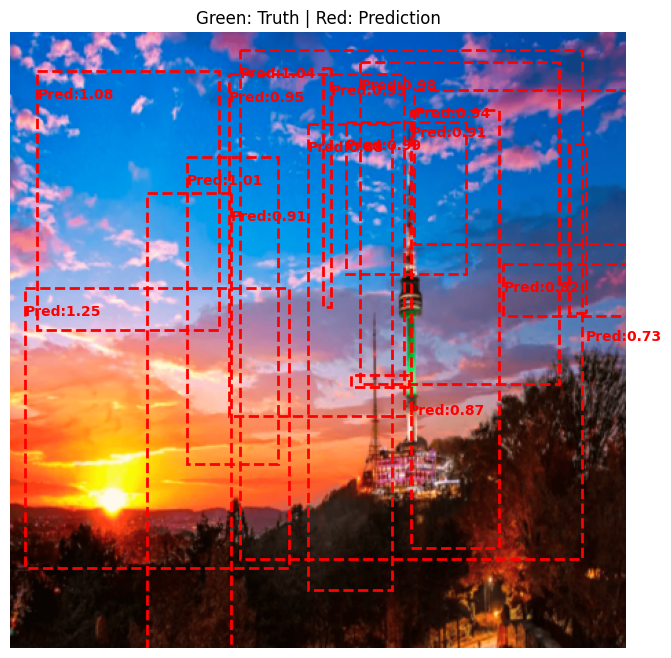

--- [Inference Result]: image (3).png ---


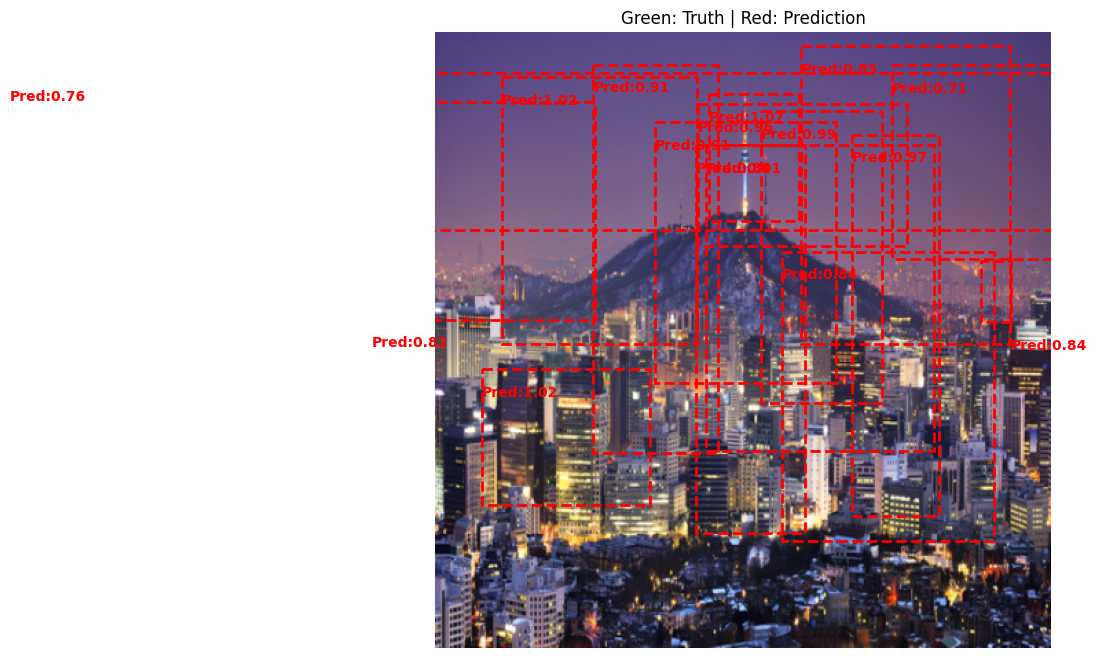

--- [Inference Result]: image (7).png ---


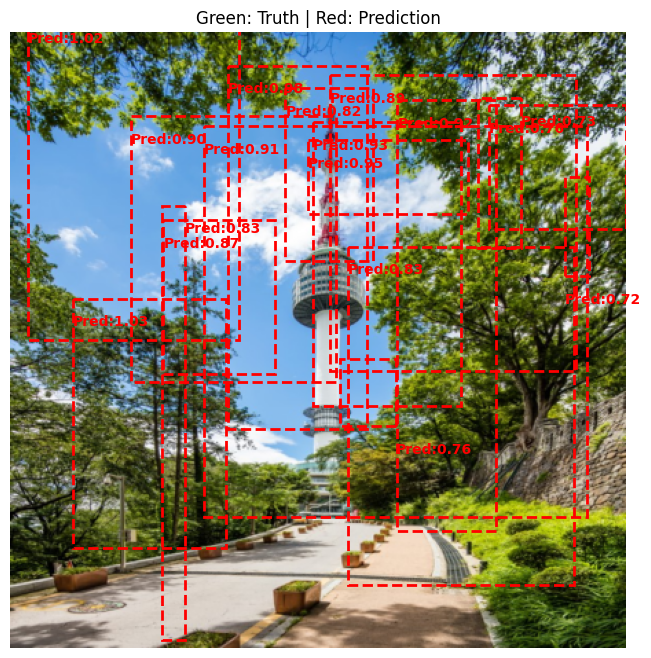

--- [Inference Result]: image (9).png ---


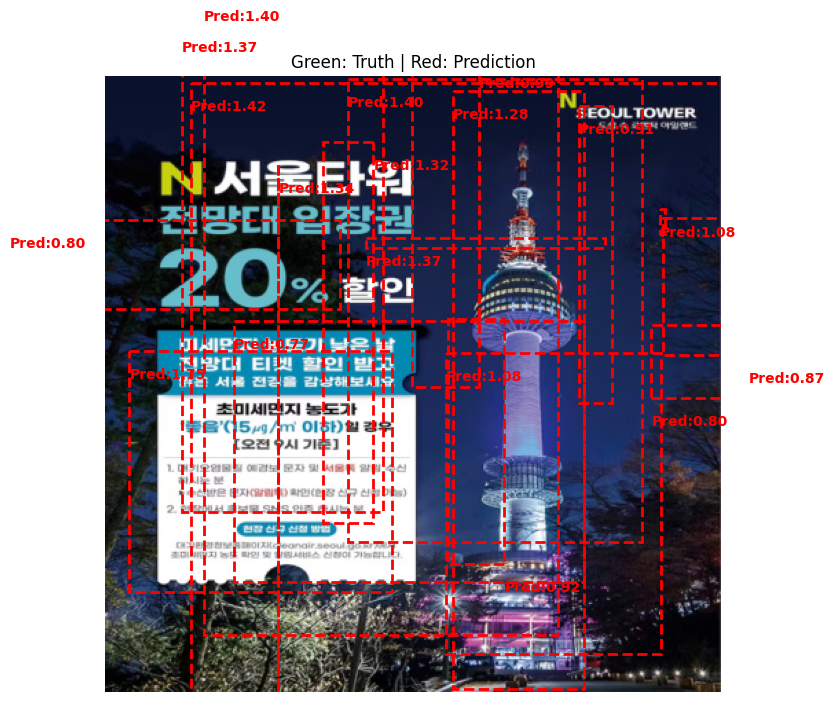

--- [Inference Result]: image (8).png ---


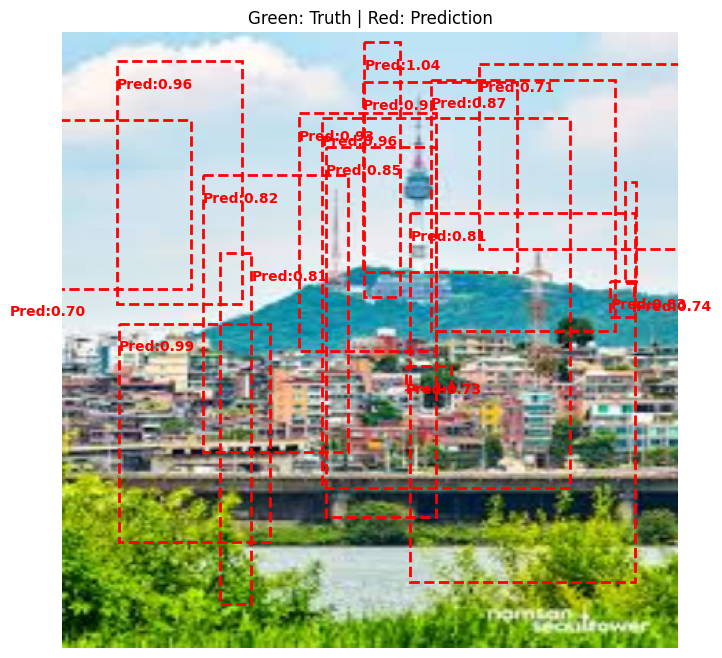

In [ ]:
import os
from PIL import Image
import torch

# 1. 경로 설정 및 모델 모드 변경
example_path = '/content/example'
model.eval()

# PNG 파일 리스트 가져오기
example_images = [f for f in os.listdir(example_path) if f.endswith('.png')]

# 2. 추론 루프
# 오탐이 많으므로 문턱값을 0.7 정도로 높게 잡아서 확실한 것만 보게 설정하세요.
CONF_THRESHOLD = 0.7
IOU_THRESHOLD = 0.45

print(f"총 {len(example_images)}개의 PNG 파일을 처리합니다.")

for img_name in example_images:
    img_full_path = os.path.join(example_path, img_name)

    # 이미지 로드 및 전처리
    raw_image = Image.open(img_full_path).convert("RGB")
    transformed_image = transform(raw_image).unsqueeze(0).to(DEVICE)

    with torch.no_grad():
        # 모델 예측
        predictions = model(transformed_image)

        # 텐서 -> 박스 변환
        bboxes = convert_cellboxes(predictions, S=7, C=1)
        bboxes = bboxes[0].tolist()

        # NMS를 위해 Corner(x1, y1, x2, y2) 형태로 변환
        bboxes_corners = []
        for box in bboxes:
            xc, yc, bw, bh = box[2:]
            bboxes_corners.append([box[0], box[1], xc - bw/2, yc - bh/2, xc + bw/2, yc + bh/2])

        # NMS 적용 (중복 박스 제거 및 낮은 신뢰도 필터링)
        nms_boxes = non_max_suppression(
            bboxes_corners,
            iou_threshold=IOU_THRESHOLD,
            threshold=CONF_THRESHOLD
        )

        # 시각화용 cx, cy, w, h로 재변환
        final_preds = []
        for box in nms_boxes:
            x1, y1, x2, y2 = box[2:]
            final_preds.append([box[0], box[1], (x1+x2)/2, (y1+y2)/2, x2-x1, y2-y1])

    # 3. 시각화 (정답 없이 예측값만 표시)
    print(f"--- [Inference Result]: {img_name} ---")
    if len(final_preds) == 0:
        print("검출된 객체가 없습니다. (Threshold를 낮춰보세요)")

    # 이전에 정의한 plot_comparison 함수를 활용하되 gt_boxes는 빈 리스트로 전달
    plot_comparison(transformed_image[0], final_preds, gt_boxes=[])

In [ ]:
def get_best_prediction(predictions, S=7, C=1):
    """
    predictions: [1, S*S*(C+B*5)] 형태의 모델 출력
    단 하나의 가장 신뢰도 높은 박스 리스트를 반환합니다.
    """
    # 1. 텐서 리셰이프 [S, S, 11]
    predictions = predictions.reshape(S, S, C + 10).to("cpu")

    # 2. 모든 박스의 Confidence 추출
    conf1 = predictions[..., 0]   # 첫 번째 박스의 신뢰도 [7, 7]
    conf2 = predictions[..., 5]   # 두 번째 박스의 신뢰도 [7, 7]

    # 두 박스 신뢰도를 합쳐서 최대값 찾기 [2, 7, 7]
    combined_conf = torch.stack([conf1, conf2], dim=0)
    max_val, max_idx = torch.max(combined_conf.view(-1), dim=0)

    # 3. 최대값 인덱스를 (박스번호, 행, 열)로 변환
    # max_idx는 0~97 사이의 값 (2 * 7 * 7 = 98)
    box_num = max_idx // (S * S)
    rem = max_idx % (S * S)
    row = rem // S
    col = rem % S

    # 4. 해당 위치의 박스 데이터 추출 [x, y, w, h]
    if box_num == 0:
        box_data = predictions[row, col, 1:5]
    else:
        box_data = predictions[row, col, 6:10]

    # 5. 셀 상대 좌표 -> 이미지 전체 절대 좌표 (0~1) 변환
    x_global = (box_data[0] + col) / S
    y_global = (box_data[1] + row) / S
    w_global = box_data[2]
    h_global = box_data[3]

    # [class_idx, confidence, x, y, w, h]
    return [[0, max_val.item(), x_global.item(), y_global.item(), w_global.item(), h_global.item()]]

In [ ]:
import os
from PIL import Image

example_path = '/content/example'
model.eval()

# 폴더 내 PNG 파일 리스트
example_images = [f for f in os.listdir(example_path) if f.endswith('.png')]

print(f"총 {len(example_images)}개의 파일에 대해 Argmax 추론을 시작합니다.")

for img_name in example_images:
    img_full_path = os.path.join(example_path, img_name)

    # 이미지 로드 및 전처리
    raw_image = Image.open(img_full_path).convert("RGB")
    transformed_image = transform(raw_image).unsqueeze(0).to(DEVICE)

    with torch.no_grad():
        # 모델 예측
        outputs = model(transformed_image)

        # Argmax: 가장 높은 확률의 박스 하나만 가져오기
        best_box = get_best_prediction(outputs, S=7, C=1)

    # 시각화 (gt_boxes는 없으므로 빈 리스트)
    print(f"--- [Best Detection]: {img_name} (Conf: {best_box[0][1]:.4f}) ---")
    plot_comparison(transformed_image[0], best_box, gt_boxes=[])